In [1]:
import pandas as pd
from sklearn.datasets import make_classification

In [10]:
X, y = make_classification(
    n_samples=200,          # Match the 200 rows in the original dataset
    n_features=2,           # 2 features: CGPA and IQ
    n_informative=2,        # Both features carry useful signal
    n_redundant=0,          # No redundant features
    n_clusters_per_class=2, # Creates 4 total cluster centers across 2 classes
    class_sep=1.5,          # Controls how far apart clusters are from each other
    random_state=42         # For reproducible results
)

In [12]:
y

array([1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0,
       1, 0])

In [13]:
df = pd.read_csv('student_clustering.csv')

In [14]:
df.head()

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110


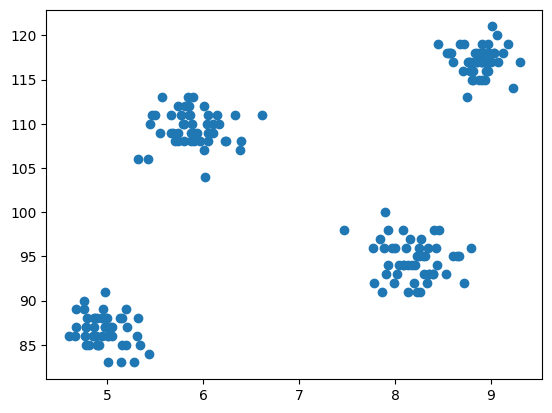

In [17]:
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
plt.scatter(df['cgpa'],df['iq'])

In [21]:
from sklearn.cluster import KMeans
wcss = []

for i in range (1,11):
    km = KMeans(n_clusters=i)
    km.fit_predict(df)
    wcss.append(km.inertia_)

In [22]:
wcss

[29957.898287999997,
 4184.14127,
 2364.0055834200834,
 681.96966,
 587.7764274703558,
 412.22876915069054,
 295.43918959431915,
 240.75513461897907,
 203.01423562643663,
 200.8133430332806]

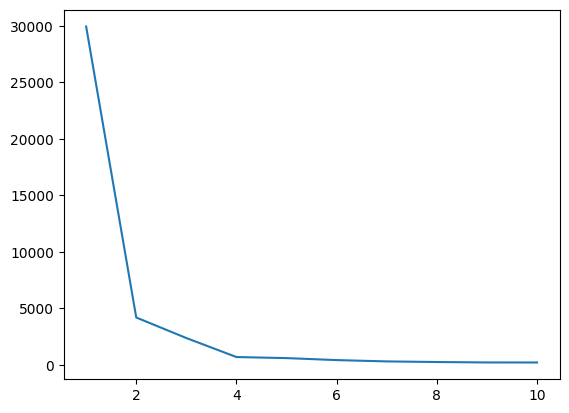

In [23]:
plt.plot(range(1,11),wcss)

In [24]:
X = df.iloc[:,:].values
km = KMeans(n_clusters=4)
y_mean = km.fit_predict(X)

In [25]:
y_mean

array([2, 3, 0, 0, 3, 3, 0, 1, 3, 0, 2, 3, 0, 2, 3, 0, 3, 0, 3, 3, 0, 2,
       0, 2, 2, 0, 2, 1, 0, 3, 1, 3, 1, 3, 0, 0, 1, 3, 2, 3, 2, 0, 0, 2,
       1, 1, 0, 3, 1, 3, 2, 2, 1, 0, 1, 3, 3, 1, 3, 1, 3, 0, 0, 1, 2, 1,
       0, 2, 3, 0, 3, 1, 0, 2, 3, 1, 3, 1, 2, 0, 0, 1, 3, 2, 1, 2, 1, 3,
       1, 3, 1, 1, 0, 2, 0, 0, 1, 0, 2, 1, 3, 2, 2, 1, 2, 2, 0, 2, 1, 1,
       0, 1, 3, 3, 0, 1, 0, 3, 1, 2, 2, 3, 0, 1, 0, 2, 0, 3, 2, 0, 0, 3,
       2, 2, 3, 1, 3, 2, 0, 0, 0, 2, 3, 2, 2, 1, 2, 1, 3, 2, 1, 2, 1, 1,
       2, 0, 3, 1, 3, 0, 2, 1, 3, 0, 1, 2, 3, 2, 2, 1, 1, 3, 1, 2, 2, 0,
       1, 3, 2, 1, 1, 3, 3, 3, 0, 2, 0, 0, 1, 3, 0, 0, 2, 2, 0, 2, 1, 3,
       3, 1], dtype=int32)

In [30]:
X[y_mean == 0,1]

array([ 93.,  97.,  98.,  94.,  97.,  95.,  91.,  98.,  92.,  98.,  94.,
        96.,  96.,  96.,  93.,  94.,  96.,  96.,  95.,  93.,  95.,  94.,
        92.,  91.,  92.,  95.,  94.,  95.,  92.,  94.,  91.,  95.,  93.,
        97.,  98.,  96.,  93., 100.,  96.,  94.,  95.,  93.,  92.,  98.,
        96.,  93.,  91.,  93.,  94.,  96.])

In [31]:
X[y_mean == 0,0]

array([8.36, 8.27, 8.41, 8.09, 8.16, 8.31, 7.87, 7.47, 7.78, 7.93, 8.04,
       7.77, 8.  , 8.43, 8.02, 8.14, 8.12, 8.34, 8.65, 8.53, 8.29, 7.93,
       8.72, 8.14, 8.2 , 8.67, 8.18, 8.61, 7.99, 8.08, 8.26, 8.25, 8.4 ,
       7.84, 8.08, 8.25, 8.3 , 7.9 , 7.97, 8.21, 8.23, 8.35, 8.33, 8.46,
       7.89, 7.91, 8.23, 8.4 , 8.44, 8.79])

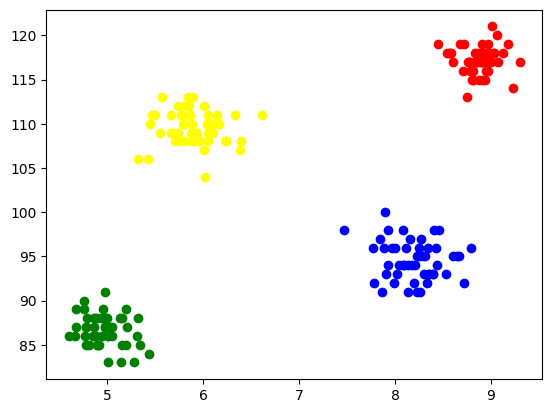

In [34]:
plt.scatter(X[y_mean == 0,0],X[y_mean == 0,1],color='blue')
plt.scatter(X[y_mean == 1,0],X[y_mean == 1,1],color='red')
plt.scatter(X[y_mean == 2,0],X[y_mean == 2,1],color='green')
plt.scatter(X[y_mean == 3,0],X[y_mean == 3,1],color='yellow')

In [35]:
from sklearn.datasets import make_blobs

centroids = [(-5,-5,5),(5,5,-5),(3.5,-2.5,4),(-2.5,2.5,-4)]
cluster_std = [1,1,1,1]

X,y = make_blobs(n_samples=200,cluster_std=cluster_std,centers=centroids,n_features=3,random_state=1)

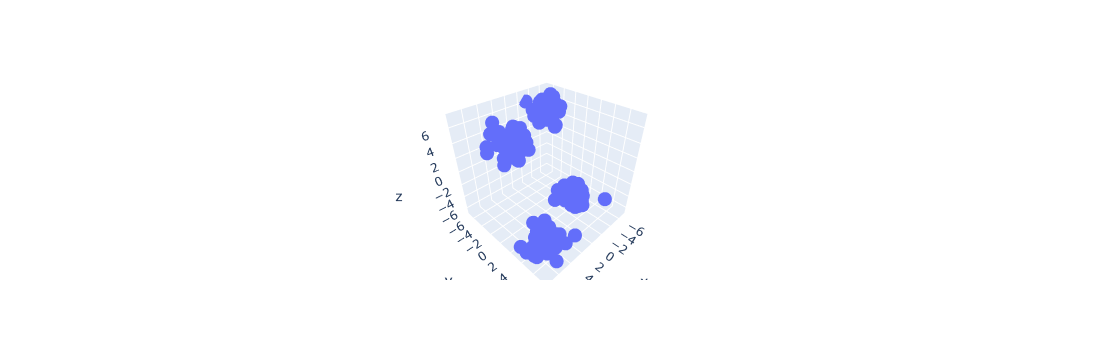

In [37]:
import plotly.express as px
fig = px.scatter_3d(x=X[:,0], y=X[:,1], z=X[:,2])
fig.show()

In [38]:
wcss = []
for i in range(1,21):
    km = KMeans(n_clusters=i)
    km.fit_predict(X)
    wcss.append(km.inertia_)

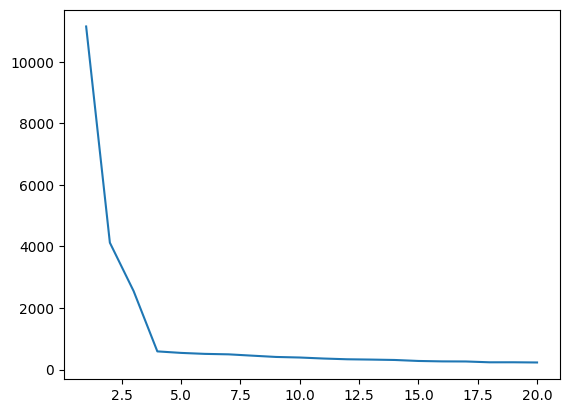

In [39]:
plt.plot(range(1,21),wcss)

In [40]:
km = KMeans(n_clusters=4)
y_pred = km.fit_predict(X)

In [41]:

df = pd.DataFrame()

df['col1'] = X[:,0]
df['col2'] = X[:,1]
df['col3'] = X[:,2]
df['label'] = y_pred

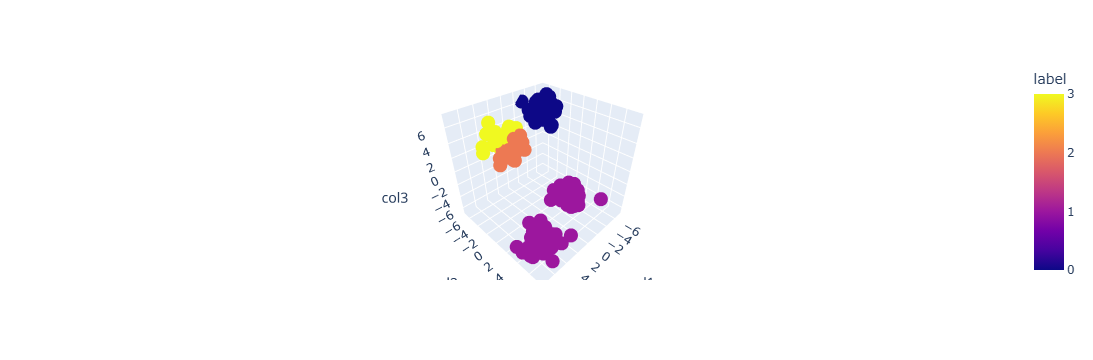

In [46]:
fig = px.scatter_3d(df,x='col1', y='col2', z='col3', color='label')
fig.show()